In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost openpyxl joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from xgboost import XGBRegressor

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Model evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Dataset splitting
from sklearn.model_selection import train_test_split

# Save models
import joblib


In [3]:
# Load the Excel dataset
df = pd.read_excel("Online Retail.xlsx")


In [5]:
print("Dataset Shape:", df.shape)




Dataset Shape: (541909, 8)


In [9]:
print("Columns in dataset:")
print(df.columns.tolist())

Columns in dataset:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [11]:
print("Missing values in each column:")
df.isnull().sum()

Missing values in each column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [13]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [14]:
# Count duplicate records before cleaning
duplicate_count = df.duplicated().sum()

print("Duplicate rows before cleaning:", duplicate_count)

# Remove duplicate records
df = df.drop_duplicates()

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows before cleaning: 5268
Duplicate rows after cleaning: 0
Dataset shape after removing duplicates: (536641, 8)


In [15]:
# Identify cancelled invoices
cancelled_orders = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Total cancelled transaction rows:", len(cancelled_orders))
print("Unique cancelled invoices:", cancelled_orders["InvoiceNo"].nunique())

Total cancelled transaction rows: 9251
Unique cancelled invoices: 3836


In [16]:
# Remove invoices starting with C
df = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Cancelled transactions remaining:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Dataset shape after removing cancellations:", df.shape)

Cancelled transactions remaining: 0
Dataset shape after removing cancellations: (527390, 8)


In [17]:
# Count negative and zero quantities
negative_quantity = (df["Quantity"] < 0).sum()
zero_quantity = (df["Quantity"] == 0).sum()

# Count negative and zero prices
negative_price = (df["UnitPrice"] < 0).sum()
zero_price = (df["UnitPrice"] == 0).sum()

print("Negative quantities:", negative_quantity)
print("Zero quantities:", zero_quantity)

print("Negative prices:", negative_price)
print("Zero prices:", zero_price)

Negative quantities: 1336
Zero quantities: 0
Negative prices: 2
Zero prices: 2510


In [18]:
# Keep only valid sales transactions
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

print("Dataset shape after cleaning:", df.shape)

print("Negative quantities remaining:", (df["Quantity"] < 0).sum())
print("Invalid prices remaining:", (df["UnitPrice"] <= 0).sum())

Dataset shape after cleaning: (524878, 8)
Negative quantities remaining: 0
Invalid prices remaining: 0


In [19]:
# Convert InvoiceDate to datetime format
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Create a separate Date column
df["Date"] = df["InvoiceDate"].dt.date

# Convert Date into datetime format
df["Date"] = pd.to_datetime(df["Date"])

print("InvoiceDate datatype:", df["InvoiceDate"].dtype)
print("Date datatype:", df["Date"].dtype)

print("Earliest transaction:", df["Date"].min())
print("Latest transaction:", df["Date"].max())

InvoiceDate datatype: datetime64[ns]
Date datatype: datetime64[ns]
Earliest transaction: 2010-12-01 00:00:00
Latest transaction: 2011-12-09 00:00:00


In [20]:
# Calculate revenue for each transaction
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Display sample records
df[["StockCode", "Quantity", "UnitPrice", "Revenue"]].head()

,StockCode,Quantity,UnitPrice,Revenue
0,85123A,6,2.55,15.30
1,71053,6,3.39,20.34
2,84406B,8,2.75,22.00
3,84029G,6,3.39,20.34
4,84029E,6,3.39,20.34


In [21]:
print("Total Transactions:", len(df))

print("Total Products:", df["StockCode"].nunique())

print("Total Units Sold:", df["Quantity"].sum())

print("Total Revenue: £", round(df["Revenue"].sum(), 2))

print("Average Transaction Revenue: £",
      round(df["Revenue"].mean(), 2))

Total Transactions: 524878
Total Products: 3922
Total Units Sold: 5572420
Total Revenue: £ 10642110.8
Average Transaction Revenue: £ 20.28


In [22]:
daily_sales = df.groupby("Date").agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Revenue", "sum"),
    Total_Transactions=("InvoiceNo", "nunique")
).reset_index()

daily_sales.head()

,Date,Total_Quantity,Total_Revenue,Total_Transactions
0,2010-12-01,26818,58776.79,127
1,2010-12-02,31264,47629.42,142
2,2010-12-03,16158,46898.63,68
3,2010-12-05,16242,31364.63,88
4,2010-12-06,21619,54624.15,102


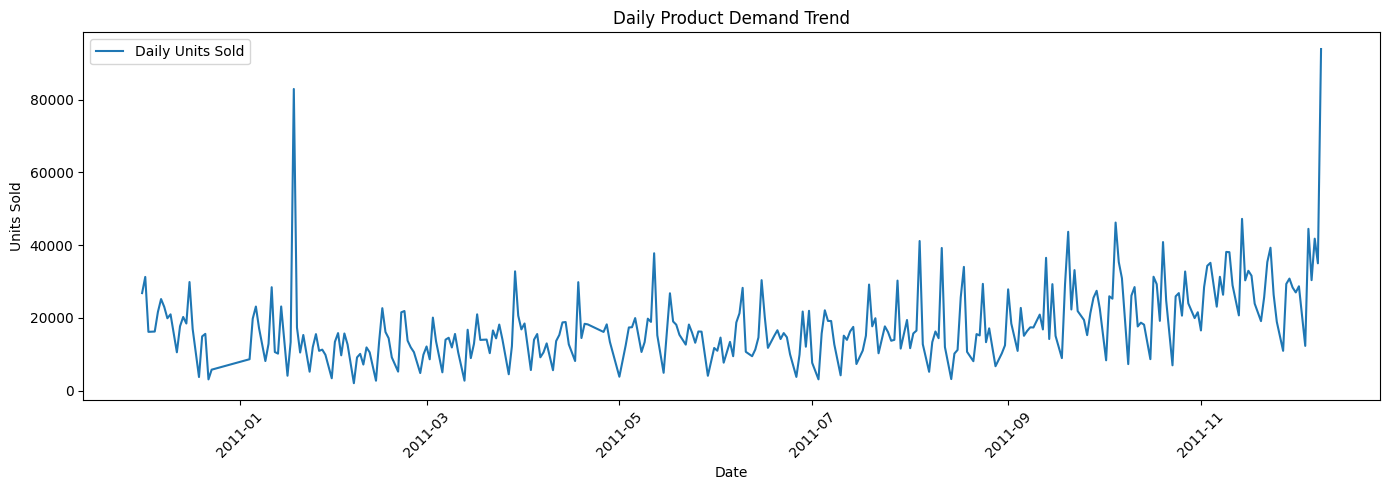

In [23]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales["Date"],
    daily_sales["Total_Quantity"],
    label="Daily Units Sold"
)

plt.title("Daily Product Demand Trend")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

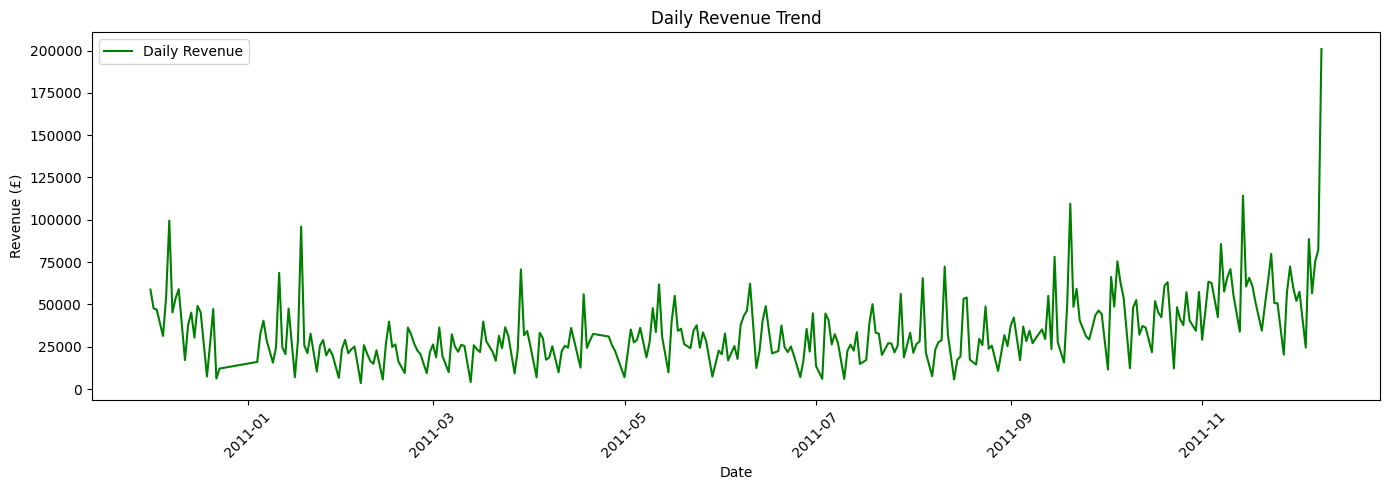

In [24]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales["Date"],
    daily_sales["Total_Revenue"],
    color="green",
    label="Daily Revenue"
)

plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
top_products = (
    df.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Units Sold:")
display(top_products)

Top 10 Products by Units Sold:


StockCode
23843     80995
23166     78033
22197     56898
84077     54951
85099B    48371
85123A    37641
21212     36396
84879     36362
23084     30739
22492     26633
Name: Quantity, dtype: int64

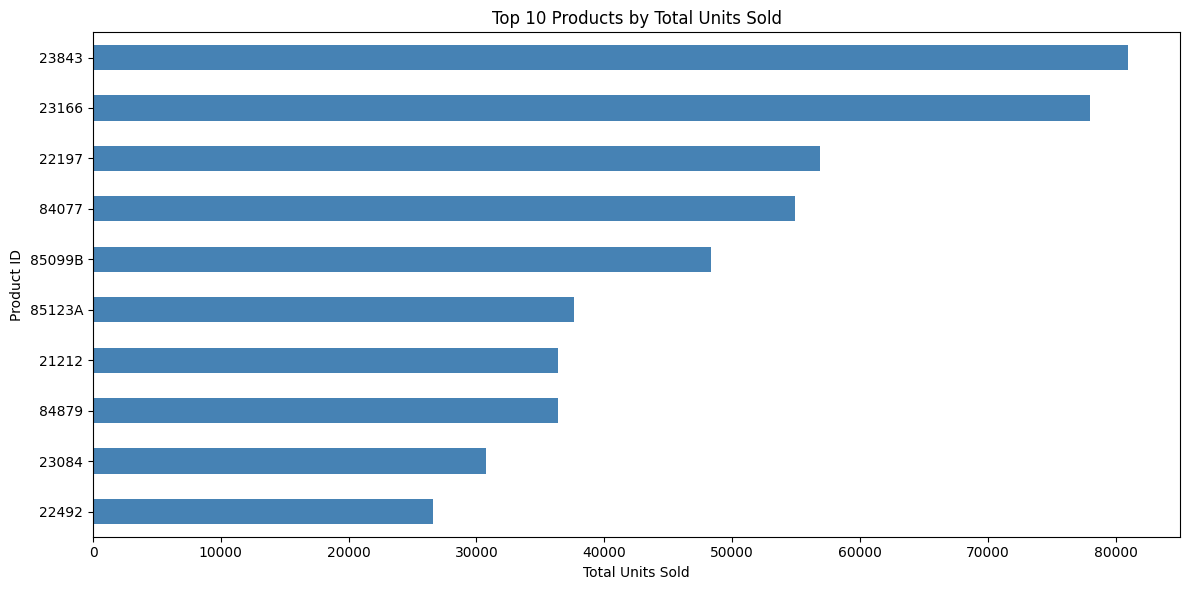

In [26]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Products by Total Units Sold")
plt.xlabel("Total Units Sold")
plt.ylabel("Product ID")

plt.tight_layout()
plt.show()

In [27]:
top_revenue_products = (
    df.groupby("StockCode")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
display(top_revenue_products)

Top 10 Products by Revenue:


StockCode
DOT       206248.77
22423     174156.54
23843     168469.60
85123A    104462.75
47566      99445.23
85099B     94159.81
23166      81700.92
POST       78101.88
M          77750.27
23084      66870.03
Name: Revenue, dtype: float64

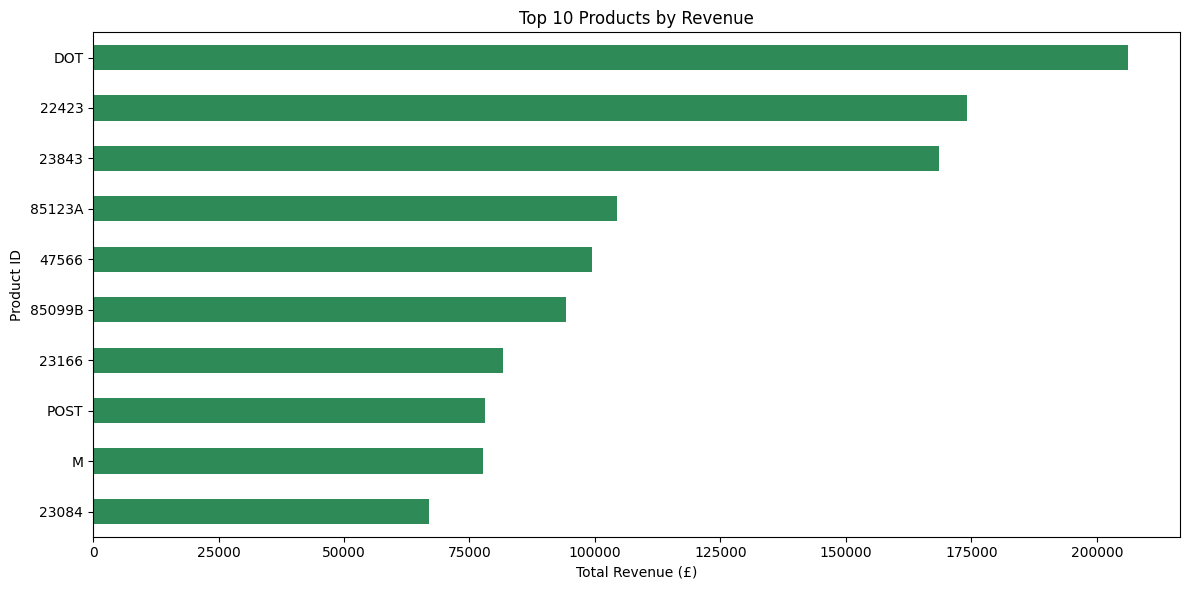

In [28]:
plt.figure(figsize=(12, 6))

top_revenue_products.sort_values().plot(
    kind="barh",
    color="seagreen"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Product ID")

plt.tight_layout()
plt.show()

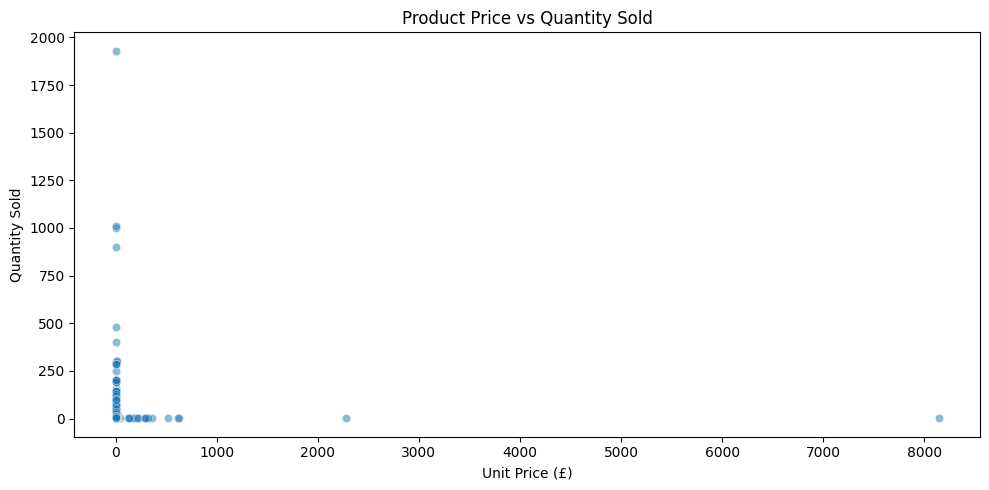

In [29]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df.sample(5000, random_state=42),
    x="UnitPrice",
    y="Quantity",
    alpha=0.5
)

plt.title("Product Price vs Quantity Sold")
plt.xlabel("Unit Price (£)")
plt.ylabel("Quantity Sold")

plt.tight_layout()
plt.show()

In [30]:
Q1 = df["Quantity"].quantile(0.25)
Q3 = df["Quantity"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

outliers = df[
    (df["Quantity"] < lower_limit) |
    (df["Quantity"] > upper_limit)
]

print("Total quantity outliers:", len(outliers))

Q1: 1.0
Q3: 11.0
IQR: 10.0
Lower Limit: -14.0
Upper Limit: 26.0
Total quantity outliers: 27111


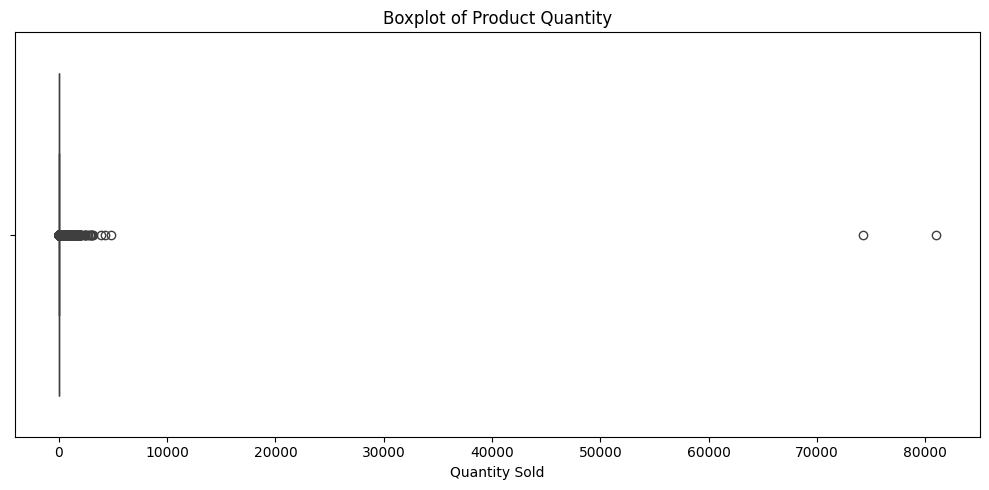

In [31]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Quantity"])

plt.title("Boxplot of Product Quantity")
plt.xlabel("Quantity Sold")

plt.tight_layout()
plt.show()

In [32]:
largest_transactions = df.nlargest(10, "Quantity")[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "Date", "Country"]
]

display(largest_transactions)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Date,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,2011-10-27,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,2011-05-27,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,2011-02-22,United Kingdom
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,2011-07-19,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,2011-01-11,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,2011-04-18,United Kingdom
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,2011-11-02,United Kingdom
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,2010-12-02,United Kingdom


In [33]:
# Inspect the two unusually large transactions
extreme_transactions = df[
    df["Quantity"] >= 70000
]

display(extreme_transactions[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "Revenue",
     "CustomerID", "Country"]
])

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346.0,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0,United Kingdom


In [34]:
# Remove only the two investigated extreme invoices
extreme_invoice_ids = ["541431", "581483"]

df = df[
    ~df["InvoiceNo"].astype(str).isin(extreme_invoice_ids)
].copy()

print("Remaining extreme transactions:",
      df["InvoiceNo"].astype(str).isin(extreme_invoice_ids).sum())

print("Updated dataset shape:", df.shape)

Remaining extreme transactions: 0
Updated dataset shape: (524876, 10)


In [35]:
# Group sales by product and date
product_daily = df.groupby(
    ["StockCode", "Date"]
).agg(
    Daily_Demand=("Quantity", "sum"),
    Daily_Revenue=("Revenue", "sum"),
    Average_Price=("UnitPrice", "mean"),
    Total_Transactions=("InvoiceNo", "nunique")
).reset_index()

# Display the result
display(product_daily.head(10))

,StockCode,Date,Daily_Demand,Daily_Revenue,Average_Price,Total_Transactions
0,10002,2010-12-01,60,51.00,0.850,2
1,10002,2010-12-02,1,0.85,0.850,1
2,10002,2010-12-03,8,12.47,1.390,3
3,10002,2010-12-05,1,0.85,0.850,1
4,10002,2010-12-06,25,22.06,1.255,2
5,10002,2010-12-07,8,13.28,1.660,3
6,10002,2010-12-08,13,11.86,1.255,2
7,10002,2010-12-09,44,39.02,1.012,5
8,10002,2010-12-10,48,40.80,0.850,2
9,10002,2010-12-13,27,25.38,1.390,3


In [36]:
print("Total product-date records:", len(product_daily))

print("Unique products:", product_daily["StockCode"].nunique())

print("Unique dates:", product_daily["Date"].nunique())

print("Start date:", product_daily["Date"].min())

print("End date:", product_daily["Date"].max())

Total product-date records: 276146
Unique products: 3921
Unique dates: 305
Start date: 2010-12-01 00:00:00
End date: 2011-12-09 00:00:00


In [37]:
# Generate all dates between the first and last transaction
all_dates = pd.date_range(
    start=product_daily["Date"].min(),
    end=product_daily["Date"].max(),
    freq="D"
)

print("Total calendar days:", len(all_dates))
print("Total products:", product_daily["StockCode"].nunique())

Total calendar days: 374
Total products: 3921


In [38]:
# Find the 30 products with the highest total demand
top_30_products = (
    product_daily.groupby("StockCode")["Daily_Demand"]
    .sum()
    .sort_values(ascending=False)
    .head(30)
    .index
)

# Filter product-level data
product_daily_top = product_daily[
    product_daily["StockCode"].isin(top_30_products)
].copy()

print("Selected products:", product_daily_top["StockCode"].nunique())
print("Records before filling missing dates:", len(product_daily_top))

Selected products: 30
Records before filling missing dates: 7500


In [39]:
# Create a complete product-date combination
complete_index = pd.MultiIndex.from_product(
    [top_30_products, all_dates],
    names=["StockCode", "Date"]
)

# Set product and date as index, then fill missing dates
product_daily_complete = (
    product_daily_top
    .set_index(["StockCode", "Date"])
    .reindex(complete_index)
    .reset_index()
)

# Fill missing sales-related values with zero
product_daily_complete["Daily_Demand"] = (
    product_daily_complete["Daily_Demand"].fillna(0)
)

product_daily_complete["Daily_Revenue"] = (
    product_daily_complete["Daily_Revenue"].fillna(0)
)

product_daily_complete["Total_Transactions"] = (
    product_daily_complete["Total_Transactions"].fillna(0)
)

print("Records after filling missing dates:", len(product_daily_complete))
print("Missing demand values:", product_daily_complete["Daily_Demand"].isna().sum())

product_daily_complete.head()

Records after filling missing dates: 11220
Missing demand values: 0


,StockCode,Date,Daily_Demand,Daily_Revenue,Average_Price,Total_Transactions
0,22197,2010-12-01,271.0,246.51,0.985455,10.0
1,22197,2010-12-02,74.0,62.90,0.850000,7.0
2,22197,2010-12-03,67.0,91.78,1.457500,4.0
3,22197,2010-12-04,0.0,0.00,NaN,0.0
4,22197,2010-12-05,81.0,68.85,0.850000,6.0


In [40]:
# Sort records by product and date
product_daily_complete = product_daily_complete.sort_values(
    ["StockCode", "Date"]
).reset_index(drop=True)

# Fill missing prices using the last known price for each product
product_daily_complete["Average_Price"] = (
    product_daily_complete
    .groupby("StockCode")["Average_Price"]
    .transform(lambda x: x.ffill())
)

# Fill any remaining missing prices using the product's median price
product_daily_complete["Average_Price"] = (
    product_daily_complete
    .groupby("StockCode")["Average_Price"]
    .transform(lambda x: x.fillna(x.median()))
)

print(
    "Missing average prices:",
    product_daily_complete["Average_Price"].isna().sum()
)

product_daily_complete.head(10)

Missing average prices: 0


,StockCode,Date,Daily_Demand,Daily_Revenue,Average_Price,Total_Transactions
0,15036,2010-12-01,0.0,0.00,0.830,0.0
1,15036,2010-12-02,48.0,36.00,0.750,3.0
2,15036,2010-12-03,15.0,12.84,1.015,2.0
3,15036,2010-12-04,0.0,0.00,1.015,0.0
4,15036,2010-12-05,12.0,9.00,0.750,1.0
5,15036,2010-12-06,4.0,5.12,1.280,2.0
6,15036,2010-12-07,0.0,0.00,1.280,0.0
7,15036,2010-12-08,13.0,10.28,1.015,2.0
8,15036,2010-12-09,1.0,1.28,1.280,1.0
9,15036,2010-12-10,3.0,3.84,1.280,2.0


In [41]:
# Extract calendar features from Date
product_daily_complete["Day"] = product_daily_complete["Date"].dt.day

product_daily_complete["Month"] = product_daily_complete["Date"].dt.month

product_daily_complete["DayOfWeek"] = (
    product_daily_complete["Date"].dt.dayofweek
)

product_daily_complete["WeekOfYear"] = (
    product_daily_complete["Date"].dt.isocalendar().week.astype(int)
)

product_daily_complete["IsWeekend"] = (
    product_daily_complete["DayOfWeek"].isin([5, 6]).astype(int)
)

# Display the updated dataset
product_daily_complete[
    ["StockCode", "Date", "Day", "Month",
     "DayOfWeek", "WeekOfYear", "IsWeekend"]
].head(10)

,StockCode,Date,Day,Month,DayOfWeek,WeekOfYear,IsWeekend
0,15036,2010-12-01,1,12,2,48,0
1,15036,2010-12-02,2,12,3,48,0
2,15036,2010-12-03,3,12,4,48,0
3,15036,2010-12-04,4,12,5,48,1
4,15036,2010-12-05,5,12,6,48,1
5,15036,2010-12-06,6,12,0,49,0
6,15036,2010-12-07,7,12,1,49,0
7,15036,2010-12-08,8,12,2,49,0
8,15036,2010-12-09,9,12,3,49,0
9,15036,2010-12-10,10,12,4,49,0


In [42]:
# Sort data before creating lag features
product_daily_complete = product_daily_complete.sort_values(
    ["StockCode", "Date"]
).reset_index(drop=True)

# Previous days' demand for each product
product_daily_complete["Lag_1"] = (
    product_daily_complete.groupby("StockCode")["Daily_Demand"].shift(1)
)

product_daily_complete["Lag_7"] = (
    product_daily_complete.groupby("StockCode")["Daily_Demand"].shift(7)
)

product_daily_complete["Lag_14"] = (
    product_daily_complete.groupby("StockCode")["Daily_Demand"].shift(14)
)

product_daily_complete["Lag_28"] = (
    product_daily_complete.groupby("StockCode")["Daily_Demand"].shift(28)
)

# Display the new features
product_daily_complete[
    ["StockCode", "Date", "Daily_Demand",
     "Lag_1", "Lag_7", "Lag_14", "Lag_28"]
].head(35)

,StockCode,Date,Daily_Demand,Lag_1,Lag_7,Lag_14,Lag_28
0,15036,2010-12-01,0.0,NaN,NaN,NaN,NaN
1,15036,2010-12-02,48.0,0.0,NaN,NaN,NaN
2,15036,2010-12-03,15.0,48.0,NaN,NaN,NaN
3,15036,2010-12-04,0.0,15.0,NaN,NaN,NaN
4,15036,2010-12-05,12.0,0.0,NaN,NaN,NaN
5,15036,2010-12-06,4.0,12.0,NaN,NaN,NaN
6,15036,2010-12-07,0.0,4.0,NaN,NaN,NaN
7,15036,2010-12-08,13.0,0.0,0.0,NaN,NaN
8,15036,2010-12-09,1.0,13.0,48.0,NaN,NaN
9,15036,2010-12-10,3.0,1.0,15.0,NaN,NaN


In [43]:
# Calculate rolling averages using only previous days
product_daily_complete["Rolling_Mean_7"] = (
    product_daily_complete
    .groupby("StockCode")["Daily_Demand"]
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)

product_daily_complete["Rolling_Mean_28"] = (
    product_daily_complete
    .groupby("StockCode")["Daily_Demand"]
    .transform(lambda x: x.shift(1).rolling(window=28).mean())
)

# Display the results
product_daily_complete[
    ["StockCode", "Date", "Daily_Demand",
     "Rolling_Mean_7", "Rolling_Mean_28"]
].head(35)

,StockCode,Date,Daily_Demand,Rolling_Mean_7,Rolling_Mean_28
0,15036,2010-12-01,0.0,NaN,NaN
1,15036,2010-12-02,48.0,NaN,NaN
2,15036,2010-12-03,15.0,NaN,NaN
3,15036,2010-12-04,0.0,NaN,NaN
4,15036,2010-12-05,12.0,NaN,NaN
5,15036,2010-12-06,4.0,NaN,NaN
6,15036,2010-12-07,0.0,NaN,NaN
7,15036,2010-12-08,13.0,11.285714,NaN
8,15036,2010-12-09,1.0,13.142857,NaN
9,15036,2010-12-10,3.0,6.428571,NaN


In [44]:
# Check missing values in lag and rolling features
feature_columns = [
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_28",
    "Rolling_Mean_7",
    "Rolling_Mean_28"
]

print("Missing values in forecasting features:")
print(product_daily_complete[feature_columns].isnull().sum())

print("\nTotal records:", len(product_daily_complete))

Missing values in forecasting features:
Lag_1               30
Lag_7              210
Lag_14             420
Lag_28             840
Rolling_Mean_7     210
Rolling_Mean_28    840
dtype: int64

Total records: 11220


In [45]:
# Remove rows with missing lag and rolling features
product_daily_model = product_daily_complete.dropna(
    subset=feature_columns
).copy()

product_daily_model = product_daily_model.reset_index(drop=True)

print("Records before removing missing values:", len(product_daily_complete))
print("Records after removing missing values:", len(product_daily_model))
print("Unique products:", product_daily_model["StockCode"].nunique())
print("Remaining missing values:", product_daily_model[feature_columns].isna().sum().sum())

product_daily_model.head()

Records before removing missing values: 11220
Records after removing missing values: 10380
Unique products: 30
Remaining missing values: 0


,StockCode,Date,Daily_Demand,Daily_Revenue,Average_Price,Total_Transactions,Day,Month,DayOfWeek,WeekOfYear,IsWeekend,Lag_1,Lag_7,Lag_14,Lag_28,Rolling_Mean_7,Rolling_Mean_28
0,15036,2010-12-29,0.0,0.0,0.75,0.0,29,12,2,52,0,0.0,0.0,0.0,0.0,0.0,5.750000
1,15036,2010-12-30,0.0,0.0,0.75,0.0,30,12,3,52,0,0.0,0.0,12.0,48.0,0.0,5.750000
2,15036,2010-12-31,0.0,0.0,0.75,0.0,31,12,4,52,0,0.0,0.0,7.0,15.0,0.0,4.035714
3,15036,2011-01-01,0.0,0.0,0.75,0.0,1,1,5,52,1,0.0,0.0,0.0,0.0,0.0,3.500000
4,15036,2011-01-02,0.0,0.0,0.75,0.0,2,1,6,52,1,0.0,0.0,0.0,12.0,0.0,3.500000


In [46]:
# Define input features
features = [
    "StockCode",
    "Day",
    "Month",
    "DayOfWeek",
    "WeekOfYear",
    "IsWeekend",
    "Average_Price",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_28",
    "Rolling_Mean_7",
    "Rolling_Mean_28"
]

# Define target variable
X = product_daily_model[features].copy()
y = product_daily_model["Daily_Demand"].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Feature dataset shape: (10380, 13)
Target dataset shape: (10380,)

Features:
['StockCode', 'Day', 'Month', 'DayOfWeek', 'WeekOfYear', 'IsWeekend', 'Average_Price', 'Lag_1', 'Lag_7', 'Lag_14', 'Lag_28', 'Rolling_Mean_7', 'Rolling_Mean_28']

Target:
Daily_Demand


In [47]:
# Sort the dataset chronologically
product_daily_model = product_daily_model.sort_values(
    ["Date", "StockCode"]
).reset_index(drop=True)

# Use the final 20% of dates for testing
split_date = product_daily_model["Date"].quantile(0.80)

train_data = product_daily_model[
    product_daily_model["Date"] <= split_date
].copy()

test_data = product_daily_model[
    product_daily_model["Date"] > split_date
].copy()

# Separate features and target
X_train = train_data[features]
X_test = test_data[features]

y_train = train_data["Daily_Demand"]
y_test = test_data["Daily_Demand"]

print("Split date:", split_date)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Training date range:",
      train_data["Date"].min(), "to", train_data["Date"].max())

print("Testing date range:",
      test_data["Date"].min(), "to", test_data["Date"].max())

Split date: 2011-10-01 00:00:00
Training records: 8310
Testing records: 2070
Training date range: 2010-12-29 00:00:00 to 2011-10-01 00:00:00
Testing date range: 2011-10-02 00:00:00 to 2011-12-09 00:00:00


In [48]:
# Separate categorical and numerical features
categorical_features = ["StockCode"]

numerical_features = [
    col for col in features if col not in categorical_features
]

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Categorical features:", categorical_features)
print("Number of numerical features:", len(numerical_features))
print("Total input features:", len(features))

Categorical features: ['StockCode']
Number of numerical features: 12
Total input features: 13


In [49]:
# Initialize the five regression models

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    )
}

print("Models initialized successfully:\n")

for model_name in models:
    print(model_name)

Models initialized successfully:

Linear Regression
Decision Tree
Random Forest
KNN
XGBoost


In [52]:
# Convert StockCode into a consistent string format
X_train["StockCode"] = X_train["StockCode"].astype(str)
X_test["StockCode"] = X_test["StockCode"].astype(str)

print("Training StockCode type:", X_train["StockCode"].dtype)
print("Testing StockCode type:", X_test["StockCode"].dtype)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training StockCode type: object
Testing StockCode type: object
Training data shape: (8310, 13)
Testing data shape: (2070, 13)


C:\Users\Sahil more\AppData\Local\Temp\ipykernel_11016\3703414881.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train["StockCode"] = X_train["StockCode"].astype(str)
C:\Users\Sahil more\AppData\Local\Temp\ipykernel_11016\3703414881.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test["StockCode"] = X_test["StockCode"].astype(str)


In [53]:
X_train = X_train.copy()
X_test = X_test.copy()

X_train.loc[:, "StockCode"] = X_train["StockCode"].astype(str)
X_test.loc[:, "StockCode"] = X_test["StockCode"].astype(str)

print("Training and testing datasets prepared.")
print("Missing values in X_train:", X_train.isna().sum().sum())
print("Missing values in X_test:", X_test.isna().sum().sum())

Training and testing datasets prepared.
Missing values in X_train: 0
Missing values in X_test: 0


In [54]:
# Dictionary to store trained pipelines
trained_models = {}

for model_name, model in models.items():

    print(f"Training {model_name}...")

    # Create pipeline with preprocessing and model
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Save trained pipeline in dictionary
    trained_models[model_name] = pipeline

    print(f"{model_name} trained successfully!\n")

print("All five models trained successfully.")

Training Linear Regression...
Linear Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training KNN...
KNN trained successfully!

Training XGBoost...
XGBoost trained successfully!

All five models trained successfully.


In [56]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

results = []
predictions = {}

for model_name, pipeline in trained_models.items():

    # Generate predictions
    y_pred = pipeline.predict(X_test)

    # Store predictions
    predictions[model_name] = y_pred

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Calculate WAPE
    wape = (
        np.sum(np.abs(y_test - y_pred)) / np.sum(np.abs(y_test))
    ) * 100

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2,
        "WAPE (%)": wape
    })

# Create comparison table
model_results = pd.DataFrame(results)

model_results = model_results.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

model_results

,Model,MAE,RMSE,R2 Score,WAPE (%)
0,XGBoost,83.697274,222.959491,0.127756,82.889205
1,Linear Regression,85.490793,230.707100,0.066083,84.665408
2,Random Forest,86.074666,221.142844,0.141912,85.243644
3,Decision Tree,92.652599,250.635689,-0.102229,91.758069
4,KNN,94.638454,238.117350,0.005126,93.724751


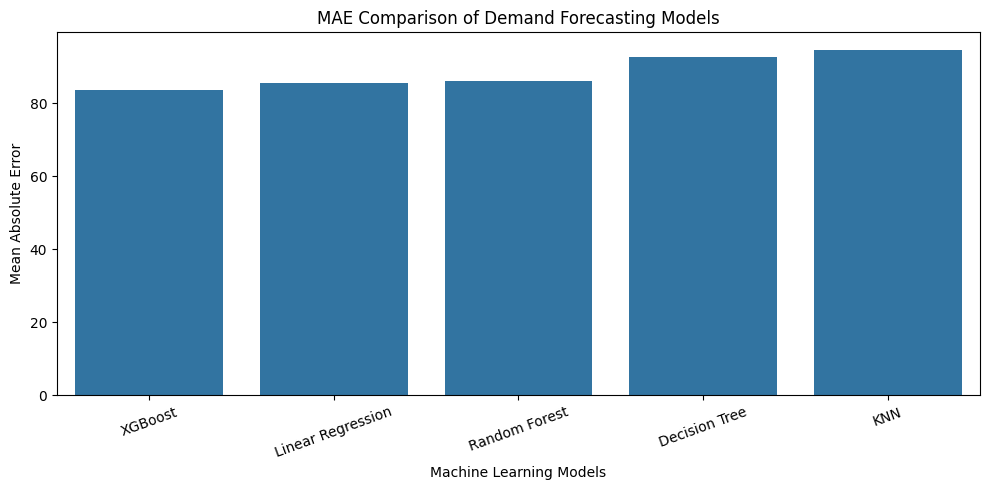

In [57]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="MAE"
)

plt.title("MAE Comparison of Demand Forecasting Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

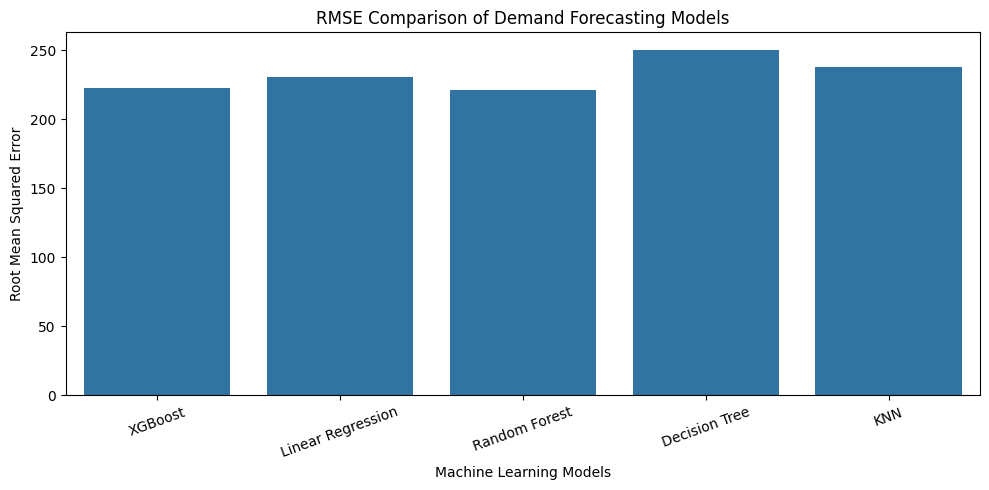

In [59]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Demand Forecasting Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

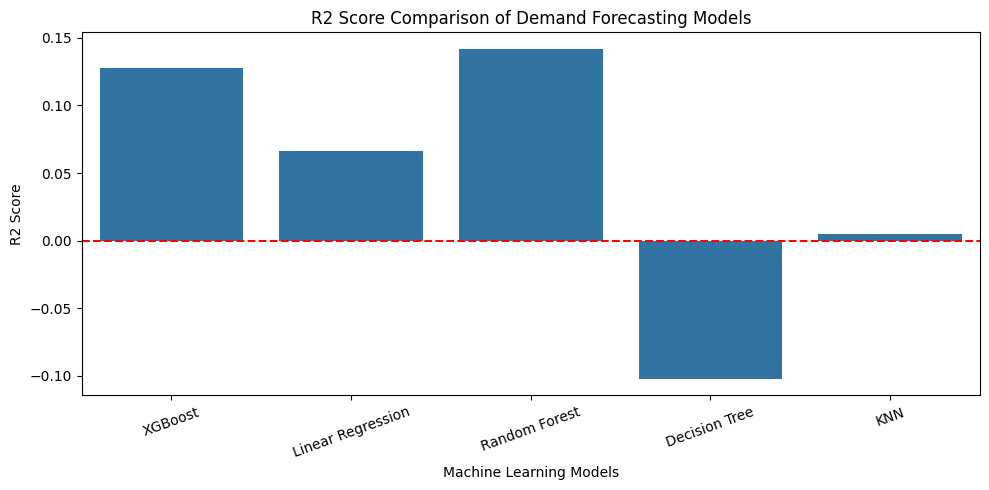

In [60]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="R2 Score"
)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("R2 Score Comparison of Demand Forecasting Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

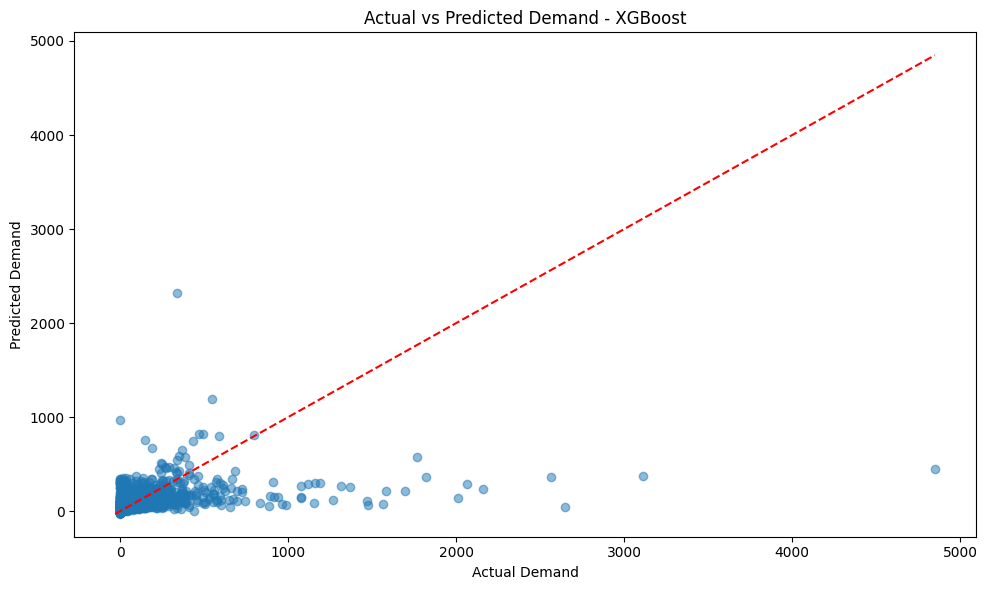

In [61]:
# Get XGBoost predictions
xgb_predictions = predictions["XGBoost"]

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    xgb_predictions,
    alpha=0.5
)

# Reference line for perfect predictions
min_value = min(y_test.min(), xgb_predictions.min())
max_value = max(y_test.max(), xgb_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--"
)

plt.title("Actual vs Predicted Demand - XGBoost")
plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.tight_layout()
plt.show()

In [62]:
# Create a comparison between actual and predicted demand
error_analysis = test_data[
    ["StockCode", "Date", "Daily_Demand"]
].copy()

error_analysis["Predicted_Demand"] = predictions["XGBoost"]

# Calculate absolute prediction error
error_analysis["Absolute_Error"] = abs(
    error_analysis["Daily_Demand"] -
    error_analysis["Predicted_Demand"]
)

# Display the 15 largest prediction errors
largest_errors = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
).head(15)

largest_errors

,StockCode,Date,Daily_Demand,Predicted_Demand,Absolute_Error
9082,84077,2011-10-27,4848.0,443.834686,4404.165314
10330,22197,2011-12-08,3111.0,371.554504,2739.445496
9079,23084,2011-10-27,2647.0,48.936821,2598.063179
10069,23084,2011-11-29,2562.0,367.345093,2194.654907
9940,22197,2011-11-25,342.0,2323.752197,1981.752197
9276,21915,2011-11-03,2158.0,240.531021,1917.468979
9400,22197,2011-11-07,2012.0,138.866562,1873.133438
9100,22197,2011-10-28,2065.0,290.798035,1774.201965
8376,21915,2011-10-04,1566.0,71.729187,1494.270813
9649,23084,2011-11-15,1697.0,218.539642,1478.460358


Demand Statistics:
count    2070.000000
mean      100.974879
std       238.787643
min         0.000000
25%         4.000000
50%        36.000000
75%       101.000000
max      4848.000000
Name: Daily_Demand, dtype: float64

Demand Distribution:
Zero-demand records: 426
Demand above 100: 519
Demand above 500: 67
Demand above 1000: 24
Maximum demand: 4848.0


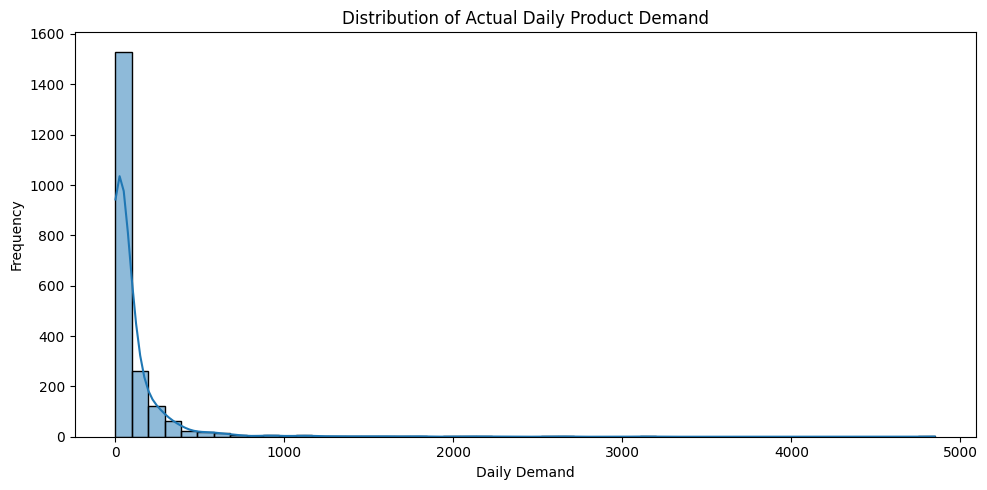

In [63]:
# Analyze actual demand in the testing dataset

print("Demand Statistics:")
print(y_test.describe())

print("\nDemand Distribution:")
print("Zero-demand records:", (y_test == 0).sum())
print("Demand above 100:", (y_test > 100).sum())
print("Demand above 500:", (y_test > 500).sum())
print("Demand above 1000:", (y_test > 1000).sum())
print("Maximum demand:", y_test.max())

# Visualize demand distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    y_test,
    bins=50,
    kde=True
)

plt.title("Distribution of Actual Daily Product Demand")
plt.xlabel("Daily Demand")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [64]:
from sklearn.compose import TransformedTargetRegressor

# Create XGBoost pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

# Apply log transformation to the target
log_xgb_model = TransformedTargetRegressor(
    regressor=xgb_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

# Train using log-transformed demand
log_xgb_model.fit(X_train, y_train)

# Predict in the original demand scale
log_xgb_predictions = log_xgb_model.predict(X_test)

# Evaluate
print("Original XGBoost MAE:",
      mean_absolute_error(y_test, predictions["XGBoost"]))

print("Log-transformed XGBoost MAE:",
      mean_absolute_error(y_test, log_xgb_predictions))

print("\nOriginal XGBoost RMSE:",
      np.sqrt(mean_squared_error(y_test, predictions["XGBoost"])))

print("Log-transformed XGBoost RMSE:",
      np.sqrt(mean_squared_error(y_test, log_xgb_predictions)))

print("\nLog-transformed XGBoost R2:",
      r2_score(y_test, log_xgb_predictions))

Original XGBoost MAE: 83.69727416330147
Log-transformed XGBoost MAE: 80.88842952325552

Original XGBoost RMSE: 222.95949099215744
Log-transformed XGBoost RMSE: 241.63020352866732

Log-transformed XGBoost R2: -0.02444488406087153


In [65]:
# Prepare product-wise prediction results
product_evaluation = test_data[
    ["StockCode", "Daily_Demand"]
].copy()

product_evaluation["Predicted_Demand"] = predictions["XGBoost"]

# Calculate error for each product
product_evaluation["Absolute_Error"] = abs(
    product_evaluation["Daily_Demand"] -
    product_evaluation["Predicted_Demand"]
)

# Calculate product-wise metrics
product_metrics = product_evaluation.groupby("StockCode").apply(
    lambda group: pd.Series({
        "MAE": mean_absolute_error(
            group["Daily_Demand"],
            group["Predicted_Demand"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group["Daily_Demand"],
            group["Predicted_Demand"]
        )),
        "Average_Actual_Demand": group["Daily_Demand"].mean(),
        "Total_Actual_Demand": group["Daily_Demand"].sum()
    }),
    include_groups=False
).reset_index()

product_metrics = product_metrics.sort_values(
    "MAE",
    ascending=True
)

product_metrics


,StockCode,MAE,RMSE,Average_Actual_Demand,Total_Actual_Demand
21,47566,28.495468,49.997569,24.231884,1672.0
3,20725,30.847165,42.667004,54.260870,3744.0
5,21213,33.735574,48.308127,32.347826,2232.0
23,84755,37.201685,50.029710,25.855072,1784.0
0,15036,39.207618,71.159930,27.942029,1928.0
25,84946,41.184849,60.268675,83.797101,5782.0
2,20724,42.877801,57.297318,67.695652,4671.0
16,22693,42.915841,81.685403,33.246377,2294.0
18,22961,43.006389,86.616001,60.652174,4185.0
7,21977,44.561948,82.429542,44.594203,3077.0


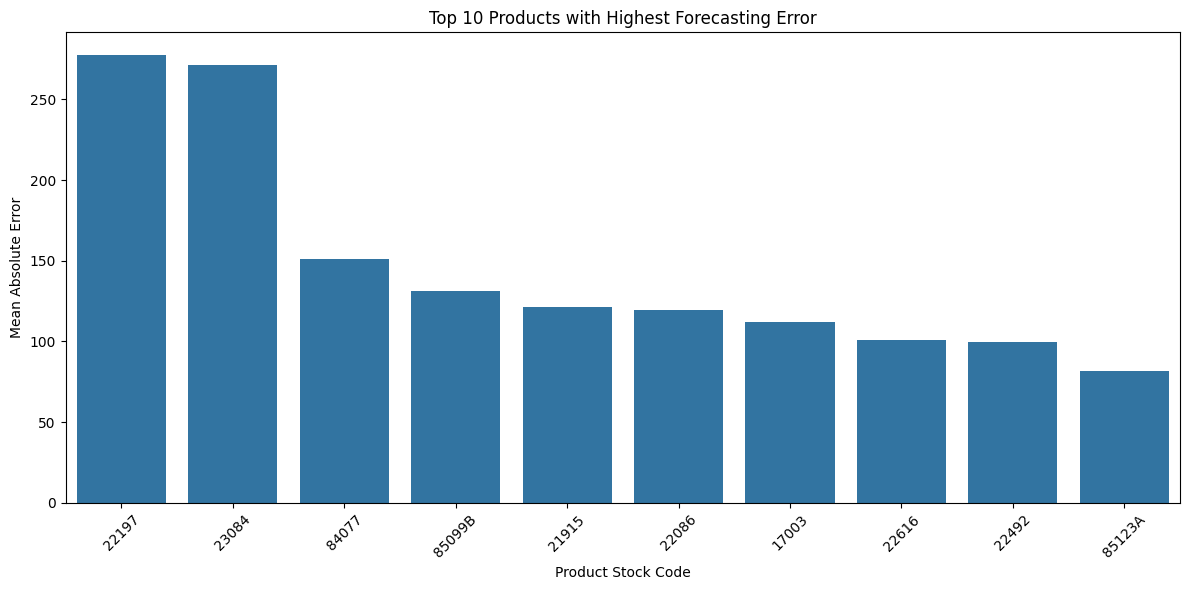

In [66]:
# Select 10 products with the highest MAE
worst_products = product_metrics.sort_values(
    by="MAE",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=worst_products,
    x="StockCode",
    y="MAE"
)

plt.title("Top 10 Products with Highest Forecasting Error")
plt.xlabel("Product Stock Code")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

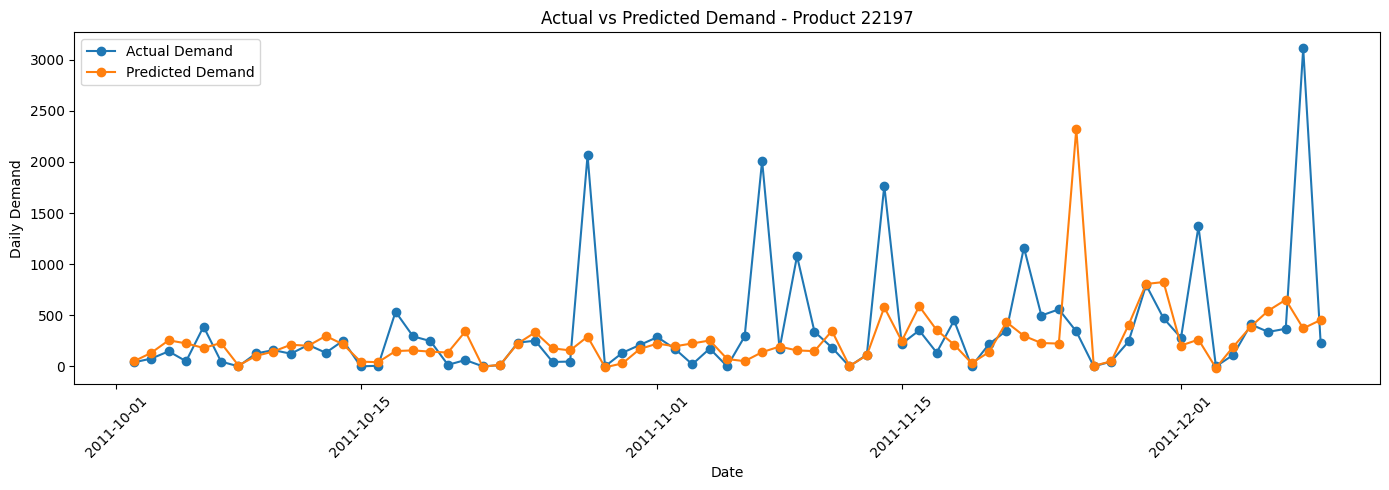

In [67]:
# Select product 22197
product_code = "22197"

product_comparison = error_analysis[
    error_analysis["StockCode"].astype(str) == product_code
].sort_values("Date")

plt.figure(figsize=(14, 5))

plt.plot(
    product_comparison["Date"],
    product_comparison["Daily_Demand"],
    label="Actual Demand",
    marker="o"
)

plt.plot(
    product_comparison["Date"],
    product_comparison["Predicted_Demand"],
    label="Predicted Demand",
    marker="o"
)

plt.title(f"Actual vs Predicted Demand - Product {product_code}")
plt.xlabel("Date")
plt.ylabel("Daily Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [68]:
# Predict demand using demand from 7 days earlier
baseline_predictions = test_data["Lag_7"].values

# Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(y_test, baseline_predictions)

# Compare with XGBoost
baseline_comparison = pd.DataFrame({
    "Model": ["7-Day Naive Baseline", "XGBoost"],
    "MAE": [
        baseline_mae,
        mean_absolute_error(y_test, predictions["XGBoost"])
    ],
    "RMSE": [
        baseline_rmse,
        np.sqrt(mean_squared_error(y_test, predictions["XGBoost"]))
    ],
    "R2 Score": [
        baseline_r2,
        r2_score(y_test, predictions["XGBoost"])
    ]
})

baseline_comparison

,Model,MAE,RMSE,R2 Score
0,7-Day Naive Baseline,104.246860,290.896146,-0.484780
1,XGBoost,83.697274,222.959491,0.127756


In [69]:
# Add baseline results to the existing model comparison
baseline_row = pd.DataFrame([{
    "Model": "7-Day Naive Baseline",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "R2 Score": baseline_r2,
    "WAPE (%)": (
        np.sum(np.abs(y_test - baseline_predictions))
        / np.sum(np.abs(y_test))
    ) * 100
}])

final_model_comparison = pd.concat(
    [model_results, baseline_row],
    ignore_index=True
)

final_model_comparison = final_model_comparison.sort_values(
    by="MAE"
).reset_index(drop=True)

final_model_comparison

,Model,MAE,RMSE,R2 Score,WAPE (%)
0,XGBoost,83.697274,222.959491,0.127756,82.889205
1,Linear Regression,85.490793,230.707100,0.066083,84.665408
2,Random Forest,86.074666,221.142844,0.141912,85.243644
3,Decision Tree,92.652599,250.635689,-0.102229,91.758069
4,KNN,94.638454,238.117350,0.005126,93.724751
5,7-Day Naive Baseline,104.246860,290.896146,-0.484780,103.240391


In [70]:
import os
import joblib

# Create folder for trained models
os.makedirs("models", exist_ok=True)

# Save all five trained model pipelines
model_files = {
    "Linear Regression": "linear_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "Random Forest": "random_forest.joblib",
    "KNN": "knn.joblib",
    "XGBoost": "xgboost.joblib"
}

for model_name, file_name in model_files.items():

    file_path = os.path.join("models", file_name)

    joblib.dump(trained_models[model_name], file_path)

    print(f"{model_name} saved at: {file_path}")

print("\nAll five trained models saved successfully!")

Linear Regression saved at: models\linear_regression.joblib
Decision Tree saved at: models\decision_tree.joblib
Random Forest saved at: models\random_forest.joblib
KNN saved at: models\knn.joblib
XGBoost saved at: models\xgboost.joblib

All five trained models saved successfully!


In [71]:
%pip install catboost

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/100.2 MB ? eta -:--:--
   - -------------------------------------- 2.6/100.2 MB 9.4 MB/s eta 0:00:11
   -- ------------------------------------- 5.2/100.2 MB 11.0 MB/s eta 0:00:09
   --- ------------------------------------ 7.6/100.2 MB 10.9 MB/s eta 0:00:09
   ---- ----------------------------------- 10.5/100.2 MB 11.5 MB/s eta 0:00:08
   ----- ---------------------------------- 13.1/100.2 MB 11.7 MB/s eta 0:00:08
   ------ --------------------------------- 16.3/100.2 MB 12.3 MB/s eta 0:00:07
   ------- -------------------------------- 18.9/100.2 MB 12.3 MB/s eta 0:00:07
   -------- ------------------------------- 21.8/100.2 MB 12.4 MB/s eta 0:00:07
   --------- ------------------------------ 24.9/100.2 MB 12.6 MB/s eta 0:00:06
   ----------- ---------------------------- 27.8/100.2 MB 12.7 MB/s eta 0:00:06
   ------------ --------------------------- 30.7/100.2 MB 12.8


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [72]:
from catboost import CatBoostRegressor

# Initialize CatBoost
catboost_model = CatBoostRegressor(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

# Train the model
catboost_model.fit(
    X_train,
    y_train,
    cat_features=["StockCode"]
)

print("CatBoost trained successfully!")

0:	learn: 153.6542456	total: 182ms	remaining: 1m 30s
100:	learn: 131.6949337	total: 4.97s	remaining: 19.6s
200:	learn: 123.8114640	total: 9.16s	remaining: 13.6s
300:	learn: 115.6403767	total: 13.2s	remaining: 8.74s
400:	learn: 109.3040079	total: 17.7s	remaining: 4.37s
499:	learn: 104.1005728	total: 21.8s	remaining: 0us
CatBoost trained successfully!


In [73]:
# Generate predictions
catboost_predictions = catboost_model.predict(X_test)

# Calculate evaluation metrics
catboost_mae = mean_absolute_error(y_test, catboost_predictions)

catboost_rmse = np.sqrt(
    mean_squared_error(y_test, catboost_predictions)
)

catboost_r2 = r2_score(y_test, catboost_predictions)

catboost_wape = (
    np.sum(np.abs(y_test - catboost_predictions))
    / np.sum(np.abs(y_test))
) * 100

print("CatBoost Evaluation Results")
print("----------------------------")
print("MAE:", catboost_mae)
print("RMSE:", catboost_rmse)
print("R2 Score:", catboost_r2)
print("WAPE (%):", catboost_wape)

CatBoost Evaluation Results
----------------------------
MAE: 79.85422874989712
RMSE: 225.90114645715246
R2 Score: 0.10458775632304784
WAPE (%): 79.08326245217495


In [74]:
catboost_row = pd.DataFrame([{
    "Model": "CatBoost",
    "MAE": catboost_mae,
    "RMSE": catboost_rmse,
    "R2 Score": catboost_r2,
    "WAPE (%)": catboost_wape
}])

updated_model_comparison = pd.concat(
    [final_model_comparison, catboost_row],
    ignore_index=True
)

updated_model_comparison = updated_model_comparison.sort_values(
    by="MAE"
).reset_index(drop=True)

updated_model_comparison

,Model,MAE,RMSE,R2 Score,WAPE (%)
0,CatBoost,79.854229,225.901146,0.104588,79.083262
1,XGBoost,83.697274,222.959491,0.127756,82.889205
2,Linear Regression,85.490793,230.707100,0.066083,84.665408
3,Random Forest,86.074666,221.142844,0.141912,85.243644
4,Decision Tree,92.652599,250.635689,-0.102229,91.758069
5,KNN,94.638454,238.117350,0.005126,93.724751
6,7-Day Naive Baseline,104.246860,290.896146,-0.484780,103.240391


In [75]:
import os
import joblib

# Create models directory
os.makedirs("models", exist_ok=True)

# Save the five existing ML pipelines
for model_name, pipeline in trained_models.items():

    file_name = model_name.lower().replace(" ", "_") + ".joblib"

    joblib.dump(
        pipeline,
        os.path.join("models", file_name)
    )

    print(f"Saved: {file_name}")

# Save CatBoost separately
joblib.dump(
    catboost_model,
    "models/catboost.joblib"
)

print("Saved: catboost.joblib")

print("\nAll six ML models saved successfully!")

Saved: linear_regression.joblib
Saved: decision_tree.joblib
Saved: random_forest.joblib
Saved: knn.joblib
Saved: xgboost.joblib
Saved: catboost.joblib

All six ML models saved successfully!


In [76]:
# Save final model comparison results
updated_model_comparison.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")
print("\nSaved file: model_comparison.csv")

updated_model_comparison

Model comparison saved successfully!

Saved file: model_comparison.csv


,Model,MAE,RMSE,R2 Score,WAPE (%)
0,CatBoost,79.854229,225.901146,0.104588,79.083262
1,XGBoost,83.697274,222.959491,0.127756,82.889205
2,Linear Regression,85.490793,230.707100,0.066083,84.665408
3,Random Forest,86.074666,221.142844,0.141912,85.243644
4,Decision Tree,92.652599,250.635689,-0.102229,91.758069
5,KNN,94.638454,238.117350,0.005126,93.724751
6,7-Day Naive Baseline,104.246860,290.896146,-0.484780,103.240391


In [77]:
# Save the cleaned product-level forecasting dataset
product_daily_model.to_csv(
    "demandiq_processed_data.csv",
    index=False
)

print("Processed dataset saved successfully!")
print("File: demandiq_processed_data.csv")
print("Records:", len(product_daily_model))
print("Products:", product_daily_model["StockCode"].nunique())
print("Date range:",
      product_daily_model["Date"].min(),
      "to",
      product_daily_model["Date"].max())

Processed dataset saved successfully!
File: demandiq_processed_data.csv
Records: 10380
Products: 30
Date range: 2010-12-29 00:00:00 to 2011-12-09 00:00:00


In [78]:
import os

model_directory = "models"

print("Saved Model Files:\n")

for file_name in sorted(os.listdir(model_directory)):
    if file_name.endswith(".joblib"):
        file_path = os.path.join(model_directory, file_name)

        print(
            file_name,
            "| Size:",
            round(os.path.getsize(file_path) / 1024, 2),
            "KB"
        )

print("\nTotal saved models:",
      len([f for f in os.listdir(model_directory)
           if f.endswith(".joblib")]))

Saved Model Files:

catboost.joblib | Size: 673.71 KB
decision_tree.joblib | Size: 55.66 KB
knn.joblib | Size: 2795.41 KB
linear_regression.joblib | Size: 4.31 KB
random_forest.joblib | Size: 12138.32 KB
xgboost.joblib | Size: 403.78 KB

Total saved models: 6


In [79]:
import joblib
import os

# Load the saved CatBoost model
loaded_catboost = joblib.load("models/catboost.joblib")

# Select one test record
sample_input = X_test.iloc[[0]]

# Generate prediction
sample_prediction = loaded_catboost.predict(sample_input)

print("Model loaded successfully!")
print("Product StockCode:", sample_input["StockCode"].iloc[0])
print("Predicted Daily Demand:", round(float(sample_prediction[0]), 2))
print("Actual Daily Demand:", y_test.iloc[0])

Model loaded successfully!
Product StockCode: 15036
Predicted Daily Demand: 0.58
Actual Daily Demand: 0.0


In [80]:
def predict_product_demand(product_code, model_name="CatBoost"):

    if model_name == "CatBoost":
        model = loaded_catboost
    else:
        model = trained_models[model_name]

    # Get the latest available record for the selected product
    product_history = product_daily_model[
        product_daily_model["StockCode"].astype(str) == str(product_code)
    ].sort_values("Date")

    if product_history.empty:
        raise ValueError("Product not found!")

    # Select the latest feature record
    latest_record = product_history.iloc[[-1]][features].copy()

    latest_record["StockCode"] = latest_record["StockCode"].astype(str)

    # Predict demand
    prediction = model.predict(latest_record)

    return max(0, float(prediction[0]))


# Test the forecasting function
result = predict_product_demand("15036")

print("Product: 15036")
print("Predicted next-day demand:", round(result, 2))

Product: 15036
Predicted next-day demand: 23.33
